# Non-linear static analysis with pyfe3d.solver

The geometrically non-linear analyses of `pyfe3d.solver.Analysis` receive the
callables of a model: the external and internal force vectors and the
stiffness matrices. This example builds these callables for pyfe3d elements
and uses them in five problems:

1. a simply supported plate with immovable edges under a uniform pressure,
   solved with a Newton-Raphson loop written by hand and with `Analysis`;
2. the same plate under a central point load, with the deflection prescribed
   instead of the load;
3. the plate with a configuration-dependent load, the piston-theory
   aerodynamic load;
4. the snap-through of the shallow von Mises truss of Crisfield (1991),
   traced with the arc-length methods;
5. the snap-through of a low sinusoidal arch of `BeamC` elements, compared
   with the limit loads of Fung and Kaplan (1952).

The theory is in [Non-linear static analyses](../nonlinear_analyses.rst),
[The Newton-Raphson method](../newton_raphson_method.rst),
[Arc-length methods](../arc_length_methods.rst) and
[Convergence criteria](../convergence_criteria.rst). The full references are
at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, csc_matrix

from pyfe3d import (DOF, DOUBLE, INT, BeamC, BeamCData, BeamCProbe, Quad4R,
                    Quad4RData, Quad4RProbe)
from pyfe3d.beamprop import BeamProp
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import (Analysis, crisfield_weights, crisfield_zeta,
                           is_symmetric, solve)

## Equilibrium and the tangent stiffness matrix

Equilibrium is the null residual

$$
\boldsymbol{R}(\boldsymbol{u}, \lambda) = \boldsymbol{F}_{int}(\boldsymbol{u})
- \lambda \boldsymbol{F}_{ext} = \boldsymbol{0}
$$

with the load factor $\lambda$. The internal forces of
`update_fint(..., nonlinear=1)` come from the von Kármán strains of the
elements, and $\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_G$, of `update_KC0`, `update_KCNL` and `update_KG`, is their
exact Jacobian, so the Newton-Raphson iterations $\boldsymbol{K}_T \delta
\boldsymbol{u} = -\boldsymbol{R}$ converge quadratically near the solution.

The class below wraps a list of elements into the four callables of
`Analysis`, with the vectors and matrices of all the dofs: `calc_fext` the
external forces times the load factor `inc`, `calc_fint` the internal forces,
`calc_kC` $\boldsymbol{K}_{C0}$, or $\boldsymbol{K}_{C0} +
\boldsymbol{K}_{CNL}$ when `NLgeom=True`, and `calc_kG` $\boldsymbol{K}_G$.
The elements share one probe, so `update_probe_xe` and `update_probe_ue` are
called before each element routine. Every call of `calc_fint` is recorded,
to follow the iterations:

In [2]:
class Model(object):
    def __init__(self, elements, data, prop, x, N, fext):
        self.elements = elements
        self.data = data
        self.prop = prop
        self.x = x
        self.N = N
        self.fext = fext
        n = len(elements)
        self.KC0r = np.zeros(data.KC0_SPARSE_SIZE*n, dtype=INT)
        self.KC0c = np.zeros(data.KC0_SPARSE_SIZE*n, dtype=INT)
        KC0v = np.zeros(data.KC0_SPARSE_SIZE*n, dtype=DOUBLE)
        self.KCNLr = np.zeros(data.KCNL_SPARSE_SIZE*n, dtype=INT)
        self.KCNLc = np.zeros(data.KCNL_SPARSE_SIZE*n, dtype=INT)
        self.KGr = np.zeros(data.KG_SPARSE_SIZE*n, dtype=INT)
        self.KGc = np.zeros(data.KG_SPARSE_SIZE*n, dtype=INT)
        for elem in elements:
            elem.update_probe_xe(x)
            elem.update_KC0(self.KC0r, self.KC0c, KC0v, prop)
        self.KC0 = self.sparse(self.KC0r, self.KC0c, KC0v)
        self.fint_calls = []

    def sparse(self, r, c, v):
        return coo_matrix((v, (r, c)), shape=(self.N, self.N)).tocsr()

    def internal_forces(self, u):
        fint = np.zeros(self.N)
        for elem in self.elements:
            elem.update_probe_xe(self.x)
            elem.update_probe_ue(u)
            elem.update_fint(fint, self.prop, nonlinear=1)
        return fint

    def KCNL(self, u):
        v = np.zeros(self.data.KCNL_SPARSE_SIZE*len(self.elements))
        for elem in self.elements:
            elem.update_probe_xe(self.x)
            elem.update_probe_ue(u)
            elem.update_KCNL(self.KCNLr, self.KCNLc, v, self.prop)
        return self.sparse(self.KCNLr, self.KCNLc, v)

    def KG(self, u):
        v = np.zeros(self.data.KG_SPARSE_SIZE*len(self.elements))
        for elem in self.elements:
            elem.update_probe_xe(self.x)
            elem.update_probe_ue(u)
            elem.update_KG(self.KGr, self.KGc, v, self.prop)
        return self.sparse(self.KGr, self.KGc, v)

    # callables of pyfe3d.solver.Analysis
    def calc_fext(self, inc=1., silent=True):
        return inc*self.fext

    def calc_fint(self, c, silent=True):
        self.fint_calls.append(c.copy())
        return self.internal_forces(c)

    def calc_kC(self, c=None, NLgeom=False, silent=True):
        if c is None or not NLgeom:
            return self.KC0
        return self.KC0 + self.KCNL(c)

    def calc_kG(self, c=None, NLgeom=False, silent=True):
        return self.KG(c)

    def analysis(self, bu, uk=None, **kwargs):
        an = Analysis(self.calc_fext, self.calc_fint, self.calc_kC,
                      self.calc_kG, bu=bu, uk=uk)
        for key, value in kwargs.items():
            setattr(an, key, value)
        return an

## 1. Plate under uniform pressure

The square plate has $a = b = 1$ m, $h = 0.01$ m, $E = 70$ GPa and $\nu =
0.3$, and is meshed with 10 x 10 `Quad4R` elements. The edges are simply
supported and immovable, $u = v = w = 0$; the drilling rotations, which do not
take part in the response of a flat plate, are held. The pressure $q = 3 h
D/(0.00406 a^4)$ is the one whose linear central deflection, $0.00406\, q
a^4/D$ with $D = E h^3/(12 (1 - \nu^2))$, is $3 h$, such that the membrane
action stiffens the plate. It is lumped to the nodes with their tributary
areas:

In [3]:
def plate(nx=11, ny=11, a=1., h=0.01, E=70.e9, nu=0.3):
    b = a
    D = E*h**3/(12*(1 - nu**2))
    q = 3*h*D/(0.00406*a**4)
    prop = isotropic_plate(thickness=h, E=E, nu=nu)
    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords.flatten()
    nids = np.arange(nx*ny).reshape(nx, ny)
    connectivity = zip(nids[:-1, :-1].flatten(), nids[1:, :-1].flatten(),
                       nids[1:, 1:].flatten(), nids[:-1, 1:].flatten())
    data = Quad4RData()
    probe = Quad4RProbe()
    elements = []
    for k, (n1, n2, n3, n4) in enumerate(connectivity):
        elem = Quad4R(probe)
        elem.n1, elem.n2, elem.n3, elem.n4 = n1, n2, n3, n4
        elem.c1, elem.c2, elem.c3, elem.c4 = DOF*n1, DOF*n2, DOF*n3, DOF*n4
        elem.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        elem.init_k_KCNL = k*data.KCNL_SPARSE_SIZE
        elem.init_k_KG = k*data.KG_SPARSE_SIZE
        elem.init_k_KA_beta = k*data.KA_BETA_SPARSE_SIZE
        elem.update_rotation_matrix(x)
        elem.update_probe_xe(x)
        elements.append(elem)

    N = DOF*nx*ny
    X, Y = ncoords[:, 0], ncoords[:, 1]
    edge = (np.isclose(X, 0) | np.isclose(X, a) | np.isclose(Y, 0)
            | np.isclose(Y, b))
    bk = np.zeros(N, dtype=bool)
    bk[0::DOF] = edge
    bk[1::DOF] = edge
    bk[2::DOF] = edge
    bk[5::DOF] = True
    bu = ~bk

    wx = np.full(nx, a/(nx - 1))
    wx[[0, -1]] /= 2
    wy = np.full(ny, b/(ny - 1))
    wy[[0, -1]] /= 2
    fext = np.zeros(N)
    fext[2::DOF] = q*np.outer(wx, wy).flatten()
    center = DOF*nids[nx//2, ny//2] + 2
    return elements, data, prop, x, N, bu, fext, center, h

elements, data, prop, x, N, bu, fext, center, h = plate()
model = Model(elements, data, prop, x, N, fext)
u_lin = np.zeros(N)
u_lin[bu] = solve(model.KC0[bu, :][:, bu], fext[bu])
print('linear central deflection: w/h = %.4f' % (u_lin[center]/h))

linear central deflection: w/h = 2.9963


### A Newton-Raphson loop written by hand

The full load in a single increment, starting from $\boldsymbol{u} =
\boldsymbol{0}$: at each iteration the internal forces and $\boldsymbol{K}_T$
are evaluated at the current displacements, and the correction solves
$\boldsymbol{K}_{T_{uu}} \delta \boldsymbol{u}_u = -\boldsymbol{R}_u$. The
relative norm of the residual is printed:

In [4]:
u = np.zeros(N)
for iteration in range(20):
    R = model.internal_forces(u)[bu] - fext[bu]
    rel = np.linalg.norm(R)/np.linalg.norm(fext[bu])
    print('iteration %2d   |R|/|F_ext| = %.2e' % (iteration, rel))
    if rel < 1e-10:
        break
    KT = model.KC0 + model.KCNL(u) + model.KG(u)
    u[bu] += solve(KT[bu, :][:, bu], -R)
u_hand = u.copy()
print('central deflection: w/h = %.6f' % (u_hand[center]/h))

iteration  0   |R|/|F_ext| = 1.00e+00
iteration  1   |R|/|F_ext| = 1.91e+02
iteration  2   |R|/|F_ext| = 1.58e+01
iteration  3   |R|/|F_ext| = 1.20e+01
iteration  4   |R|/|F_ext| = 2.28e+00
iteration  5   |R|/|F_ext| = 2.06e-01
iteration  6   |R|/|F_ext| = 1.18e-03
iteration  7   |R|/|F_ext| = 4.20e-08
iteration  8   |R|/|F_ext| = 6.63e-13
central deflection: w/h = 1.094278


Far from the solution the residual first grows; near it, it falls
quadratically, each norm about the square of the previous one.

### The same with Analysis

`Analysis.static(NLgeom=True)` runs the same iterations, here with the full
load in one increment, `initialInc=1.`, and the convergence criterion of
Crisfield (1991),

$$
\zeta_i = \frac{\|\boldsymbol{R}_i\|_{\boldsymbol{d}}}{\max\left(
\|\lambda \boldsymbol{F}_{ext}\|_{\boldsymbol{d}},
\|\boldsymbol{F}_{int}(\boldsymbol{u}_i)\|_{\boldsymbol{d}}, \dots\right)}
\le \text{relTOL}
$$

with the norms over the free dofs, weighted by the weights $\boldsymbol{d}$ of
`crisfield_weights`. The criterion is evaluated below at every recorded call
of `calc_fint`, with `crisfield_zeta`:

In [5]:
model.fint_calls = []
an = model.analysis(bu, initialInc=1., relTOL=1.e-9)
increments, cs = an.static(NLgeom=True, silent=True)
u_an = cs[-1]

w = crisfield_weights(model.KC0[bu, :][:, bu])
zetas = []
for c in model.fint_calls:
    fint = model.internal_forces(c)[bu]
    zetas.append(crisfield_zeta(fint - fext[bu], fext[bu], fint, w))
print('zeta:', ' '.join('%.1e' % z for z in zetas))
print('%-22s %12s' % ('', 'w/h'))
print('%-22s %12.8f' % ('linear', u_lin[center]/h))
print('%-22s %12.8f' % ('hand-written loop', u_hand[center]/h))
print('%-22s %12.8f' % ('Analysis', u_an[center]/h))
print('relative difference, Analysis vs hand-written: %.1e'
      % (u_an[center]/u_hand[center] - 1))

zeta: 1.0e+00 9.7e-01 9.8e-01 7.8e-01 1.3e-01 7.8e-04 2.8e-08 1.1e-12
                                w/h
linear                   2.99626733
hand-written loop        1.09427794
Analysis                 1.09427794
relative difference, Analysis vs hand-written: 6.5e-14


The membrane action reduces the central deflection from $3 h$ to about $1.1
h$.

### The load-deflection curve

With smaller increments, `initialInc=0.1`, `Analysis` returns the load
factors of the converged increments and their displacements, the
equilibrium path:

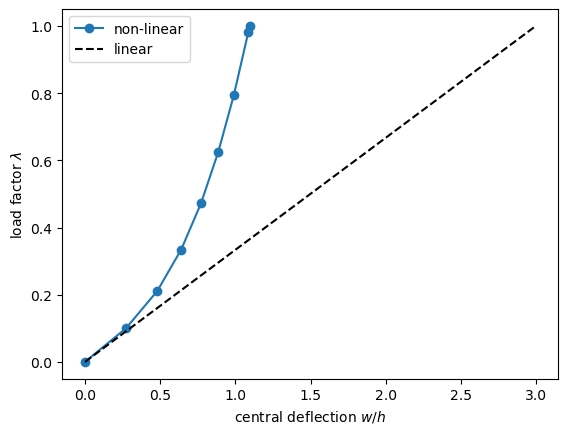

In [6]:
an = model.analysis(bu, initialInc=0.1, relTOL=1.e-9)
increments, cs = an.static(NLgeom=True, silent=True)
w_path = np.array([c[center] for c in cs])/h
plt.plot(np.r_[0, w_path], np.r_[0, increments], 'o-', label='non-linear')
plt.plot([0, u_lin[center]/h], [0, 1], 'k--', label='linear')
plt.xlabel('central deflection $w/h$')
plt.ylabel(r'load factor $\lambda$')
plt.legend()
plt.show()

## 2. Prescribed displacement

The same plate under a central point load $P$ whose linear deflection is $3
h$, first with the load prescribed. Then the central deflection $w_c$ of
that solution is prescribed instead, $\bar{u}_k = \lambda w_c$, at a dof
moved from `bu` to the constrained ones, with `uk` and no external load. The
reaction at that dof, $\boldsymbol{R}_k$ of the partitioned system of
[Boundary conditions and prescribed displacements](../boundary_conditions.rst),
equals the internal force there and must equal $P$, with the same
displacement field. Displacement control is solved with Newton-Raphson and
with the Riks method:

In [7]:
elements, data, prop, x, N, bu, _, dof, h = plate()
f = np.zeros(N)
f[dof] = 1.
model = Model(elements, data, prop, x, N, f)
w1 = solve(model.KC0[bu, :][:, bu], f[bu])[np.flatnonzero(bu) == dof][0]
P = 3*h/w1
model.fext = P*f

an = model.analysis(bu, initialInc=0.2, relTOL=1.e-10)
increments, cs = an.static(NLgeom=True, silent=True)
u_load = cs[-1]
w_c = u_load[dof]
print('load control: P = %.6e N, w/h = %.6f' % (P, w_c/h))

bu_d = bu.copy()
bu_d[dof] = False
uk = np.zeros(N)
uk[dof] = w_c
model.fext = np.zeros(N)
paths = {}
print('%-16s %16s %16s %11s %18s' % ('method', 'reaction (N)', 'P (N)',
      'rel. diff.', 'max |u - u_load|'))
for method in ['NR', 'arc_length_riks']:
    an_d = model.analysis(bu_d, uk=uk, initialInc=0.2, relTOL=1.e-10,
                          NL_method=method)
    increments_d, cs_d = an_d.static(NLgeom=True, silent=True)
    reaction = model.internal_forces(cs_d[-1])[dof]
    paths[method] = (increments_d, [model.internal_forces(c)[dof]
                                    for c in cs_d])
    print('%-16s %16.8e %16.8e %11.1e %18.2e'
          % (method, reaction, P, reaction/P - 1,
             np.abs(cs_d[-1] - u_load).max()))

load control: P = 1.660498e+04 N, w/h = 1.274070
method               reaction (N)            P (N)  rel. diff.   max |u - u_load|


NR                 1.66049794e+04   1.66049794e+04    -6.5e-12           1.39e-13


arc_length_riks    1.66049794e+04   1.66049794e+04    -5.2e-11           8.74e-13


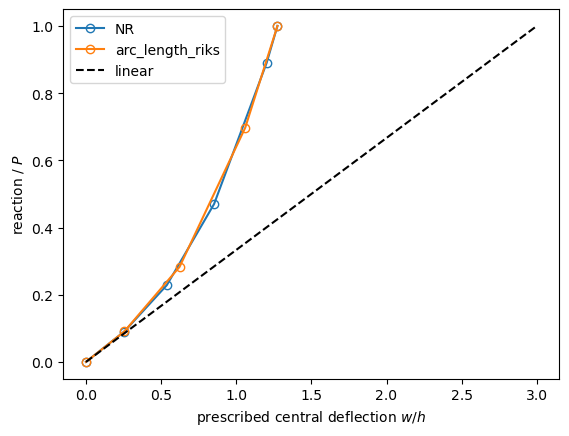

In [8]:
for method, (lbd, reactions) in paths.items():
    plt.plot(np.r_[0, lbd]*w_c/h, np.r_[0, reactions]/P, 'o-', mfc='none',
             label=method)
plt.plot([0, 3], [0, 1], 'k--', label='linear')
plt.xlabel('prescribed central deflection $w/h$')
plt.ylabel('reaction / $P$')
plt.legend()
plt.show()

The reaction grows faster than the deflection: membrane stiffening.

## 3. Configuration-dependent load

The aerodynamic load of the piston theory, $\boldsymbol{F}_a = \lambda \beta
\boldsymbol{K}_{A_\beta} \boldsymbol{u}$, with the matrix of `update_KA_beta`
of `Quad4R`, depends on the displacements. Moved to the left-hand side, it
enters the internal forces with the load factor `inc`, and its load
stiffness $-\lambda \beta \boldsymbol{K}_{A_\beta}$, unsymmetric, enters
$\boldsymbol{K}_T$; `calc_fext(c=...)` gives the load vector of the current
configuration, used by the geometrically linear analysis. See
[Load- and configuration-dependent loads](../configuration_dependent_loads.rst).
The plate is that of problem 1, and $\beta$ is chosen such that the
aerodynamic load is 20 % of the pressure load in the linear solution:

In [9]:
elements, data, prop, x, N, bu, fext, center, h = plate()
model = Model(elements, data, prop, x, N, fext)
r = np.zeros(data.KA_BETA_SPARSE_SIZE*len(elements), dtype=INT)
c = np.zeros(data.KA_BETA_SPARSE_SIZE*len(elements), dtype=INT)
v = np.zeros(data.KA_BETA_SPARSE_SIZE*len(elements), dtype=DOUBLE)
for elem in elements:
    elem.update_probe_xe(x)
    elem.update_KA_beta(r, c, v)
KA = coo_matrix((v, (r, c)), shape=(N, N)).tocsr()
u_lin = np.zeros(N)
u_lin[bu] = solve(model.KC0[bu, :][:, bu], fext[bu])
beta = 0.2*np.linalg.norm(fext[bu])/np.linalg.norm((KA @ u_lin)[bu])
BKA = beta*KA
print('K_C0 - beta*K_A symmetric:', is_symmetric((model.KC0 - BKA)[bu, :][:, bu]))

def calc_fint(c, inc=1., silent=True):
    return model.internal_forces(c) - inc*(BKA @ c)

def calc_kC(c=None, NLgeom=False, inc=1., silent=True):
    if c is None or not NLgeom:
        return model.KC0
    return model.KC0 + model.KCNL(c) - inc*BKA

def calc_fext(inc=1., silent=True, c=None):
    if c is None:
        return inc*model.fext
    return inc*(model.fext + BKA @ c)

K_C0 - beta*K_A symmetric: False


The geometrically non-linear analysis with and without the aerodynamic load,
and the geometrically linear analysis, whose load correction iterations with
`calc_fext(c=...)` must give the solution of $(\boldsymbol{K}_{C0} - \beta
\boldsymbol{K}_{A_\beta}) \boldsymbol{u} = \boldsymbol{F}_{ext}$:

In [10]:
an = Analysis(calc_fext, calc_fint, calc_kC, model.calc_kG, bu=bu)
an.initialInc = 1.
an.relTOL = 1.e-10
u_aero = an.static(NLgeom=True, silent=True)[1][-1]
R = (model.internal_forces(u_aero) - (model.fext + BKA @ u_aero))[bu]
print('non-linear, |R|/|F_ext| = %.1e' % (np.linalg.norm(R)
                                         /np.linalg.norm(model.fext[bu])))
u_dead = model.analysis(bu, initialInc=1., relTOL=1.e-10).static(
    NLgeom=True, silent=True)[1][-1]

an_lin = Analysis(calc_fext, None, calc_kC, None, bu=bu)
an_lin.relTOL = 1.e-12
an_lin.maxNumIter = 100
u_lin_aero = an_lin.static(silent=True)[1][-1]
ref = np.zeros(N)
ref[bu] = solve((model.KC0 - BKA)[bu, :][:, bu], model.fext[bu])

print('%-36s %10s' % ('', 'w/h'))
print('%-36s %10.6f' % ('non-linear, pressure only', u_dead[center]/h))
print('%-36s %10.6f' % ('non-linear, with aerodynamic load', u_aero[center]/h))
print('%-36s %10.6f' % ('linear, with aerodynamic load', u_lin_aero[center]/h))
print('%-36s %10.6f' % ('(K_C0 - beta K_A) u = F_ext', ref[center]/h))
print('linear analysis vs direct solution, max relative difference: %.1e'
      % (np.abs(u_lin_aero - ref).max()/np.abs(ref).max()))

non-linear, |R|/|F_ext| = 8.8e-13


                                            w/h
non-linear, pressure only              1.094278
non-linear, with aerodynamic load      1.093184
linear, with aerodynamic load          2.973885
(K_C0 - beta K_A) u = F_ext            2.973885
linear analysis vs direct solution, max relative difference: 2.2e-12


The aerodynamic load changes the deflection by 0.1 % in the non-linear
analysis, where the membrane stiffness of the deflected plate dominates, and
by 0.7 % in the linear one.

## 4. Snap-through of the von Mises truss

A shallow von Mises truss loaded through a linear spring of stiffness $k_s$:
dof 0 is the apex deflection $w$, positive towards the base, and dof 1 the
loaded point. With the shallow truss theory of Crisfield (1991, Sec. 1.2,
Eq. (1.7), p. 4), for two bars with $E A/l^3 = 1$ and the rise $z = 1$, the
internal force at the apex is

$$
F(w) = w^3 - 3 w^2 + 2 w
$$

$F'(w) = 3 w^2 - 6 w + 2 = 0$ gives the limit points $w = 1 \mp 1/\sqrt{3}$,
with the loads $\pm F_{lim}$, $F_{lim} = 2/(3 \sqrt{3})$, and $F = 0$ again
at $w = 2$, the inverted configuration. The spring in series carries the same
force, so the load factor at a given $w$ does not depend on its stiffness. The
callables are written directly with NumPy:

In [11]:
F_LIM = 2/(3*np.sqrt(3))

def von_mises_truss(frac, ks=10.):
    fext = np.array([0., frac*F_LIM])
    kC = csc_matrix(np.array([[2. + ks, -ks], [-ks, ks]]))

    def calc_fext(inc=1., silent=True):
        return inc*fext

    def calc_fint(c, silent=True):
        w = c[0]
        return np.array([w**3 - 3*w**2 + 2*w + ks*(c[0] - c[1]),
                         ks*(c[1] - c[0])])

    def calc_kC(c=None, NLgeom=False, silent=True):
        return kC

    def calc_kG(c=None, NLgeom=False, silent=True):
        w = c[0]
        return csc_matrix(np.array([[3*w**2 - 6*w, 0.], [0., 0.]]))

    return Analysis(calc_fext, calc_fint, calc_kC, calc_kG)

The load is $1.5 F_{lim}$. Load control would stop at the limit point; the
arc-length methods add to the equilibrium the constraint
$\Delta \boldsymbol{u}^\top \Delta \boldsymbol{u} / (\boldsymbol{u}_{ref}^\top
\boldsymbol{u}_{ref}) + \psi^2 \Delta\lambda^2 = \Delta s^2$, linearized
(Riks 1979) or solved exactly (Crisfield 1981), and follow the path through
the limit points, along which the load factor becomes negative, until the
load factor 1.0 on the inverted configuration. On the path, $\lambda = F(w)/(1.5
F_{lim})$, with the extremes $\pm 1/1.5$:

In [12]:
frac = 1.5
w_final = np.roots([1, -3, 2, -frac*F_LIM]).real.max()
print('%-22s %12s %12s %12s' % ('', 'max lambda', 'min lambda', 'final w'))
print('%-22s %12.6f %12.6f %12.6f' % ('Crisfield (1991)', 1/frac, -1/frac,
                                     w_final))
paths = {}
for method in ['arc_length_riks', 'arc_length_crisfield']:
    an = von_mises_truss(frac)
    an.NL_method = method
    an.initialInc = 0.05
    an.static(NLgeom=True, silent=True)
    inc = np.asarray(an.increments)
    w = np.array([c[0] for c in an.cs])
    paths[method] = (w, inc)
    print('%-22s %12.6f %12.6f %12.6f' % (method, inc[:-1].max(), inc.min(),
                                         w[-1]))

                         max lambda   min lambda      final w
Crisfield (1991)           0.666667    -0.666667     2.214631
arc_length_riks            0.658958    -0.658902     2.214631


arc_length_crisfield       0.664845    -0.661710     2.214631


The extremes are those of the converged increments, which sample the path
near the limit points. The final apex deflection is the root $w > 2$ of $F(w)
= 1.5 F_{lim}$:

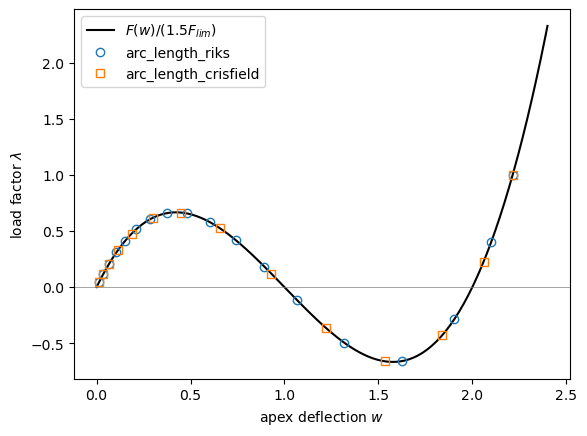

In [13]:
wplot = np.linspace(0, 2.4, 200)
plt.plot(wplot, (wplot**3 - 3*wplot**2 + 2*wplot)/(frac*F_LIM), 'k-',
         label='$F(w)/(1.5 F_{lim})$')
for (method, (w, inc)), marker in zip(paths.items(), ['o', 's']):
    plt.plot(w, inc, marker, mfc='none', label=method)
plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('apex deflection $w$')
plt.ylabel(r'load factor $\lambda$')
plt.legend()
plt.show()

## 5. Snap-through of a low sinusoidal arch

Fung and Kaplan (1952) write the equilibrium of a low arch hinged at both
ends, of initial and deflected centre lines $y_0 = \sum a_m L \sin(m \pi
x/L)$ and $y = \sum b_m L \sin(m \pi x/L)$, with the nondimensional rises
and load of their Eq. (14),

$$
\lambda_m = \frac{a_m L}{2}\sqrt{\frac{A}{I}}, \qquad
B_m = \frac{b_m L}{2}\sqrt{\frac{A}{I}}, \qquad
R = \frac{q_0 L^4}{2 \pi^4 E I}\sqrt{\frac{A}{I}}
$$

For the sinusoidal arch under the sinusoidal load $q_0 \sin(\pi x/L)$, rigid
supports and no initial thrust, the symmetric path is their Eq. (23),
$B_1^3 - B_1 (\lambda_1^2 - 1) = \lambda_1 - R$, with the upper limit point
of their Eq. (25),

$$
R_{cr} = \lambda_1 + \sqrt{\frac{4 (\lambda_1^2 - 1)^3}{27}}
$$

and the lower one at $\lambda_1 - \sqrt{4 (\lambda_1^2 - 1)^3/27}$, $B_1 =
\mp\sqrt{(\lambda_1^2 - 1)/3}$. With $\lambda_1^2 < 5.5$ the arch buckles at
the limit point, their Eq. (29), so the symmetric path is the one followed.
Here $\lambda_1 = 2.2$:

In [14]:
lam1 = 2.2
d = np.sqrt(4/27*(lam1**2 - 1)**3)
R_cr, R_low = lam1 + d, lam1 - d
B1_lim = np.sqrt((lam1**2 - 1)/3)
print('R_cr = %.6f at B1 = %.4f, lower limit load %.6f at B1 = %.4f'
      % (R_cr, B1_lim, R_low, -B1_lim))

R_cr = 5.096309 at B1 = 1.1314, lower limit load -0.696309 at B1 = -1.1314


The arch is modelled with 40 `BeamC` elements in the $x$-$z$ plane, $L =
100$, a rectangular section of thickness $t = 1$ and width 1, $E = 10^7$ and
$\nu = 0.3$, hinged at both ends ($u = w = 0$); the out-of-plane dofs $v$,
$r_x$ and $r_z$ are held at every node. The sinusoidal load is lumped to the
nodes, with the reference load $1.25 R_{cr}$, so that the load factor 1.0 is
reached only on the inverted arch, after both limit points and two null
loads. $B_1$ is computed from the deflection at mid-span:

In [15]:
def arch(lam1, R_ref, num_elements=40, L=100., t=1., b=1., E=1.e7, nu=0.3):
    A = b*t
    I = b*t**3/12
    rA = np.sqrt(A/I)
    a1L = 2*lam1/rA
    q0 = R_ref*2*np.pi**4*E*I/(L**4*rA)
    prop = BeamProp()
    prop.A = A
    prop.E = E
    prop.G = E/2/(1 + nu)
    prop.Iyy = I # bending in the x-z plane
    prop.Izz = t*b**3/12
    prop.J = b*t**3/3
    num_nodes = num_elements + 1
    xs = np.linspace(0, L, num_nodes)
    x = np.vstack((xs, 0*xs, a1L*np.sin(np.pi*xs/L))).T.flatten()
    data = BeamCData()
    probe = BeamCProbe()
    elements = []
    for k in range(num_elements):
        elem = BeamC(probe)
        elem.n1, elem.n2 = k, k + 1
        elem.c1, elem.c2 = DOF*k, DOF*(k + 1)
        elem.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        elem.init_k_KCNL = k*data.KCNL_SPARSE_SIZE
        elem.init_k_KG = k*data.KG_SPARSE_SIZE
        elem.update_rotation_matrix(0., 1., 0., x)
        elem.update_probe_xe(x)
        elements.append(elem)
    N = DOF*num_nodes
    bk = np.zeros(N, dtype=bool)
    bk[1::DOF] = True
    bk[3::DOF] = True
    bk[5::DOF] = True
    for n in (0, num_nodes - 1):
        bk[DOF*n + 0] = True
        bk[DOF*n + 2] = True
    fext = np.zeros(N)
    weights = np.full(num_nodes, L/num_elements)
    weights[[0, -1]] /= 2
    fext[2::DOF] = -q0*np.sin(np.pi*xs/L)*weights
    model = Model(elements, data, prop, x, N, fext)
    mid = DOF*(num_elements//2) + 2
    B1 = lambda u: (a1L + u[mid])/2*rA
    return model, ~bk, B1

Both arc-length methods, with increments of at most 0.05 and the default
tolerances. The limit loads of the model are the extremes of $R$ along the
converged increments:

In [16]:
R_ref = 1.25*R_cr
print('%-22s %12s %10s %12s %10s' % ('', 'upper R', 'rel. diff.', 'lower R',
                                    'rel. diff.'))
print('%-22s %12.6f %10s %12.6f %10s' % ('Fung and Kaplan (1952)', R_cr, '',
                                        R_low, ''))
arch_paths = {}
for method in ['arc_length_riks', 'arc_length_crisfield']:
    model, bu, B1 = arch(lam1, R_ref)
    an = model.analysis(bu, NL_method=method, initialInc=0.05, maxInc=0.05,
                        maxArcLength=1e6)
    increments, cs = an.static(NLgeom=True, silent=True)
    R = R_ref*np.asarray(increments)
    B1s = np.array([B1(c) for c in cs])
    arch_paths[method] = (B1s, R)
    kmin = np.argmin(R)
    kmax = np.argmax(R[:kmin])
    print('%-22s %12.6f %10.2e %12.6f %10.2e'
          % (method, R[kmax], R[kmax]/R_cr - 1, R[kmin], R[kmin]/R_low - 1))

                            upper R rel. diff.      lower R rel. diff.
Fung and Kaplan (1952)     5.096309               -0.696309           


arc_length_riks            5.084297  -2.36e-03    -0.693671  -3.79e-03


arc_length_crisfield       5.084297  -2.36e-03    -0.693671  -3.79e-03


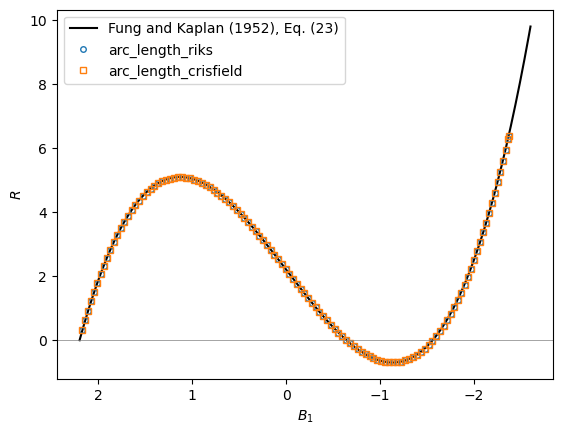

In [17]:
B1plot = np.linspace(lam1, -2.6, 300)
plt.plot(B1plot, lam1 - B1plot**3 + B1plot*(lam1**2 - 1), 'k-',
         label='Fung and Kaplan (1952), Eq. (23)')
for (method, (B1s, R)), marker in zip(arch_paths.items(), ['o', 's']):
    plt.plot(B1s, R, marker, ms=4, mfc='none', label=method)
plt.axhline(0, color='gray', lw=0.5)
plt.gca().invert_xaxis()
plt.xlabel('$B_1$')
plt.ylabel('$R$')
plt.legend()
plt.show()

The path passes both limit points and the null loads between and after them,
which the convergence criteria accept thanks to their round-off floor, see
[Non-linear static analyses](../nonlinear_analyses.rst). The limit loads of
the 40 elements are within 0.4 % of the analytical ones; part of the
difference is the sampling of the path by the converged increments.

## References

- Crisfield, M. A., A fast incremental/iterative solution procedure that
  handles "snap-through", Computers & Structures, 13(1-3), 55-62, 1981.
  https://doi.org/10.1016/0045-7949(81)90108-5
- Crisfield, M. A., Non-linear Finite Element Analysis of Solids and
  Structures, Volume 1: Essentials, John Wiley & Sons, Chichester, 1991.
- Fung, Y. C. and Kaplan, A., Buckling of low arches or curved beams of
  small curvature, NACA Technical Note 2840, National Advisory Committee for
  Aeronautics, Washington, 1952. https://ntrs.nasa.gov/citations/19930083579
- Riks, E., An incremental approach to the solution of snapping and
  buckling problems, International Journal of Solids and Structures,
  15(7), 529-551, 1979. https://doi.org/10.1016/0020-7683(79)90081-7